<a href="https://colab.research.google.com/github/Ibrohimstudent/CatBoost/blob/main/CatBoostRegressor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [38]:
!pip install legacy-cgi

In [39]:
!pip install opendatasets

In [40]:
import opendatasets as od
od.download("https://www.kaggle.com/datasets/hellbuoy/car-price-prediction")

Skipping, found downloaded files in "./car-price-prediction" (use force=True to force download)


In [41]:
!pip install catboost

In [61]:
import pandas as pd
import numpy as np
import time

from catboost import CatBoostRegressor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

In [43]:
df = pd.read_csv('/content/car-price-prediction/CarPrice_Assignment.csv')

df.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [44]:
df.shape

(205, 26)

In [45]:
X = df.drop(columns=["price", "car_ID"])
y = df["price"]

In [46]:
cat_features = X.select_dtypes(include="object").columns.tolist()

print(cat_features)

['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']


In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = CatBoostRegressor(
    random_seed=42
)

start = time.perf_counter()
model.fit(
    X_train, y_train, cat_features=cat_features
)
cat_time = time.perf_counter() - start

y_pred = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"RMSE: {rmse:.2f}")
print(f"R2: {r2:.2f}")

Learning rate set to 0.03077
0:	learn: 7593.5403482	total: 6.7ms	remaining: 6.69s
1:	learn: 7460.1556755	total: 15.2ms	remaining: 7.6s
2:	learn: 7302.9175310	total: 22.2ms	remaining: 7.38s
3:	learn: 7179.5646503	total: 28.2ms	remaining: 7.02s
4:	learn: 7036.6481087	total: 34.6ms	remaining: 6.88s
5:	learn: 6923.9136635	total: 41.1ms	remaining: 6.81s
6:	learn: 6816.2399432	total: 48.1ms	remaining: 6.83s
7:	learn: 6704.2493533	total: 54.2ms	remaining: 6.72s
8:	learn: 6587.8896107	total: 61.4ms	remaining: 6.76s
9:	learn: 6466.3532360	total: 65.2ms	remaining: 6.46s
10:	learn: 6373.0432595	total: 72.3ms	remaining: 6.5s
11:	learn: 6234.3003831	total: 78.9ms	remaining: 6.5s
12:	learn: 6140.0078072	total: 85.6ms	remaining: 6.5s
13:	learn: 6033.2962508	total: 91.1ms	remaining: 6.42s
14:	learn: 5947.5784554	total: 97.9ms	remaining: 6.43s
15:	learn: 5851.1953473	total: 104ms	remaining: 6.4s
16:	learn: 5755.6494785	total: 111ms	remaining: 6.41s
17:	learn: 5675.7288552	total: 117ms	remaining: 6.4s
1

In [48]:
X_encoded = pd.get_dummies(
    X, columns=cat_features, drop_first=True
)

In [49]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

In [50]:
model2 = LGBMRegressor(
    random_state=42
)
start = time.perf_counter()

model2.fit(X_train2, y_train2)

lgbm_time = time.perf_counter() - start

y_pred2 = model2.predict(X_test2)

lgbm_rmse = np.sqrt(mean_squared_error(y_test2, y_pred2))
lgbm_r2 = r2_score(y_test2, y_pred2)

print(f"RMSE: {lgbm_rmse:.2f}")
print(f"R2: {lgbm_r2:.2f}")

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000092 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 396
[LightGBM] [Info] Number of data points in the train set: 164, number of used features: 25
[LightGBM] [Info] Start training from score 13223.414634
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best

In [51]:
comparison = pd.DataFrame({
    "Model": ["CatBoosting", "LightGBMBoosting"],
    "RMSE": [rmse, lgbm_rmse],
    "R2": [r2, lgbm_r2],
    "Training time (s)": [cat_time, lgbm_time],
    "Kod": ["11-qator", "12-qator"]
}
)

comparison

,Model,RMSE,R2,Training time (s),Kod
0,CatBoosting,2208.070312,0.938240,6.633072,11-qator
1,LightGBMBoosting,3254.093675,0.865865,0.059176,12-qator


In [59]:
results = []

depth_values = [4, 6]
learning_rate_values = [0.03, 0.05]
iterations_values = [300, 500]

for depth in depth_values:
    for learning_rate in learning_rate_values:
        for iterations in iterations_values:

            model = CatBoostRegressor(
                depth=depth,
                learning_rate=learning_rate,
                iterations=iterations,
                loss_function="RMSE",
                verbose=0,
                random_seed=42
            )

            start = time.perf_counter()

            model.fit(
                X_train,
                y_train,
                cat_features=cat_features
            )

            train_time = time.perf_counter() - start

            y_pred = model.predict(X_test)

            rmse = np.sqrt(
                mean_squared_error(y_test, y_pred)
            )

            r2 = r2_score(y_test, y_pred)

            results.append({
                "depth": depth,
                "learning_rate": learning_rate,
                "iterations": iterations,
                "RMSE": rmse,
                "R2": r2,
                "Time": train_time
            })

In [60]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values("RMSE")

results_df

,depth,learning_rate,iterations,RMSE,R2,Time
3,4,0.05,500,2103.370030,0.943958,3.455994
7,6,0.05,500,2114.934100,0.943340,1.976963
2,4,0.05,300,2119.834641,0.943077,0.520927
1,4,0.03,500,2153.282638,0.941267,0.795401
6,6,0.05,300,2177.485738,0.939939,1.152468
0,4,0.03,300,2187.383825,0.939392,1.048748
5,6,0.03,500,2207.094222,0.938295,1.858365
4,6,0.03,300,2253.408646,0.935678,1.872831


CatBoost kategorik ustunlar ko‘p bo‘lgan datasetlarda qulayroq, chunki ularni alohida encoding qilmasdan to‘g‘ridan-to‘g‘ri ishlata oladi.
LightGBM esa katta hajmdagi datasetlarda tez ishlashi va kamroq vaqt talab qilishi bilan afzal bo‘lishi mumkin.
CatBoost'da preprocessing bosqichlari kamroq bo‘lgani uchun kod yozish va modelni tayyorlash osonroq.
LightGBM'da esa kategorik ma’lumotlar bilan ishlash uchun ko‘pincha encoding yoki boshqa preprocessing talab qilinadi.
Agar dataset kichik yoki o‘rta hajmda bo‘lib, kategorik ustunlar ko‘p bo‘lsa, men CatBoost'dan foydalanishni ma’qul ko‘raman.
Katta datasetlarda esa tezlik va hisoblash samaradorligi muhim bo‘lsa, LightGBM yaxshi variant bo‘lishi mumkin.

In [63]:
xgb_model = XGBRegressor(
    random_state=42
)

start = time.perf_counter()

xgb_model.fit(
    X_train2,
    y_train2
)

xgb_time = time.perf_counter() - start

xgb_pred = xgb_model.predict(X_test2)

xgb_rmse = np.sqrt(
    mean_squared_error(y_test2, xgb_pred)
)

xgb_r2 = r2_score(y_test2, xgb_pred)

print(f"RMSE: {xgb_rmse:.2f}")
print(f"R2: {xgb_r2:.2f}")

RMSE: 2159.42
R2: 0.94


In [70]:
results_df = pd.DataFrame({
    "Model": ["CatBoost", "LightGBMBoost", "XGBoost"],
    "RMSE": [rmse, lgbm_rmse, xgb_rmse],
    "R2": [r2, lgbm_r2, xgb_r2],
    "Training time(s)": [cat_time, lgbm_time, xgb_time]
})

results_df

,Model,RMSE,R2,Training time(s)
0,CatBoost,2114.934100,0.943340,6.633072
1,LightGBMBoost,3254.093675,0.865865,0.059176
2,XGBoost,2159.424009,0.940931,1.100667


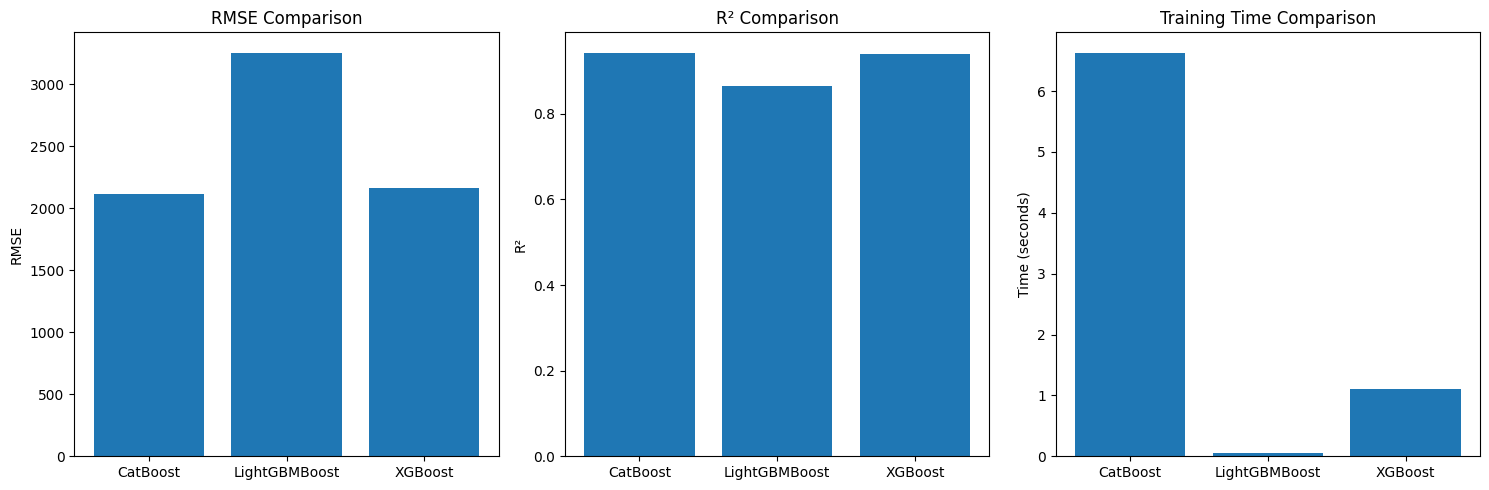

In [73]:
import matplotlib.pyplot as plt
import numpy as np

models = results_df["Model"]
x = np.arange(len(models))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

#RMSE
axes[0].bar(x, results_df["RMSE"])
axes[0].set_title("RMSE Comparison")
axes[0].set_ylabel("RMSE")
axes[0].set_xticks(x)
axes[0].set_xticklabels(models)


#R2
axes[1].bar(x, results_df["R2"])
axes[1].set_title("R² Comparison")
axes[1].set_ylabel("R²")
axes[1].set_xticks(x)
axes[1].set_xticklabels(models)


#Training Time
axes[2].bar(x, results_df["Training time(s)"])
axes[2].set_title("Training Time Comparison")
axes[2].set_ylabel("Time (seconds)")
axes[2].set_xticks(x)
axes[2].set_xticklabels(models)


plt.tight_layout()
plt.show()

In [76]:
feature_importance = model.get_feature_importance()

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": feature_importance
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

importance_df.head()

,Feature,Importance
15,enginesize,32.408503
12,curbweight,10.879547
22,citympg,9.954270
14,cylindernumber,7.567262
6,drivewheel,3.989900


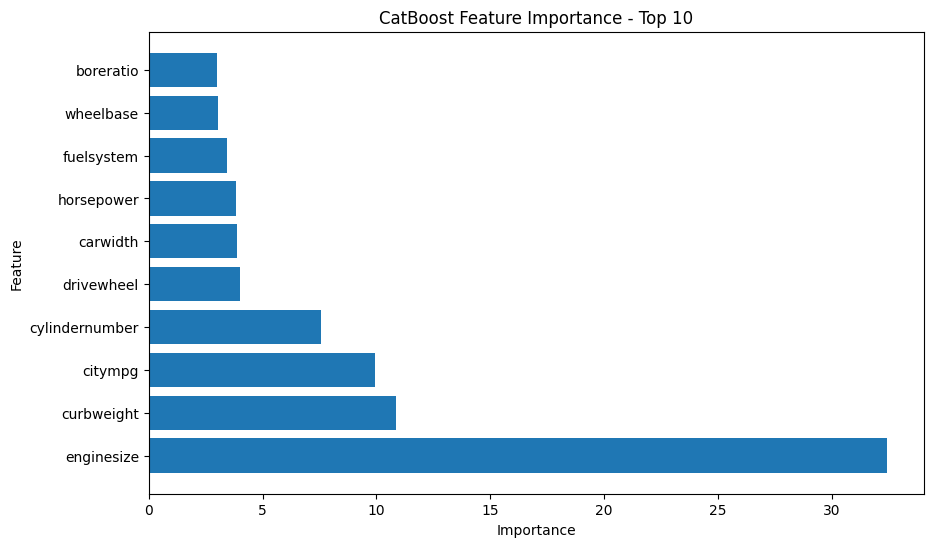

In [79]:
top_features = importance_df.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("CatBoost Feature Importance - Top 10")


plt.show()

CatBoost feature importance natijasiga ko‘ra, eng muhim ustunlar avtomobil narxiga eng katta ta’sir ko‘rsatadi. Ayniqsa, dvigatel hajmi, horsepower va avtomobil og‘irligi kabi featurelar muhim bo‘lishi mumkin. Importance qiymati yuqori bo‘lgan featurelar model uchun ko‘proq ahamiyatga ega.

In [80]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 9.9 MB/s eta 0:00:00


In [81]:
import optuna

In [84]:

def objective(trial):

    depth = trial.suggest_int("depth", 4, 10)

    learning_rate = trial.suggest_float(
        "learning_rate", 0.01, 0.2, log=True
    )

    l2_leaf_reg = trial.suggest_float(
        "l2_leaf_reg", 1, 10
    )

    model = CatBoostRegressor(
        depth=depth,
        learning_rate=learning_rate,
        l2_leaf_reg=l2_leaf_reg,
        iterations=500,
        loss_function="RMSE",
        verbose=0,
        random_seed=42
    )

    model.fit(
        X_train,
        y_train,
        cat_features=cat_features
    )

    y_pred = model.predict(X_test)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    return rmse

In [87]:
study = optuna.create_study(
    direction="maximize"
)

study.optimize(
    objective,
    n_trials=20
)

[I 2026-09-28 07:04:37,582] A new study created in memory with name: no-name-84d5940e-40cb-4b10-8f50-c6745f5b39ed
[I 2026-09-28 07:04:39,566] Trial 0 finished with value: 2113.3513058216736 and parameters: {'depth': 6, 'learning_rate': 0.07566053781327338, 'l2_leaf_reg': 6.821955271379854}. Best is trial 0 with value: 2113.3513058216736.
[I 2026-09-28 07:04:50,076] Trial 1 finished with value: 2640.5537859904125 and parameters: {'depth': 9, 'learning_rate': 0.01207440507758931, 'l2_leaf_reg': 4.419611121817679}. Best is trial 1 with value: 2640.5537859904125.
[I 2026-09-28 07:05:03,109] Trial 2 finished with value: 2455.8661326043175 and parameters: {'depth': 10, 'learning_rate': 0.04196430455655963, 'l2_leaf_reg': 3.832572066432428}. Best is trial 1 with value: 2640.5537859904125.
[I 2026-09-28 07:05:16,917] Trial 3 finished with value: 2353.029875217786 and parameters: {'depth': 10, 'learning_rate': 0.16769151352251874, 'l2_leaf_reg': 8.072120250644401}. Best is trial 1 with value: 2

In [89]:
print("Best parameters:")
print(study.best_params)

print("Best RMSE:")
print(study.best_value)

Best parameters:
{'depth': 10, 'learning_rate': 0.010778148003538358, 'l2_leaf_reg': 8.499690057395467}
Best RMSE:
2837.4145582250662
